# Heart Disease Prediction

**Question:** Can routine clinical measurements predict whether a patient has heart disease, and which factors matter most?

**Data:** UCI Cleveland Heart Disease dataset: 303 patients, 13 clinical features, binary target (1 = heart disease).

**Approach:** exploratory analysis, then a majority-class baseline, decision tree, logistic regression and random forest, compared on a held-out test set (30%) and with 10-fold cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, roc_curve, confusion_matrix)

df = pd.read_csv('data/heart.csv')
print('Shape:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Target balance:', df['target'].value_counts().to_dict())
print('Mean age:', round(df['age'].mean(), 1))
print(df.head().to_string())

Shape: (303, 14)
Missing values: 0
Duplicate rows: 1
Target balance: {1: 165, 0: 138}
Mean age: 54.4
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal  target
0   63    1   3       145   233    1        0      150      0      2.3      0   0     1       1
1   37    1   2       130   250    0        1      187      0      3.5      0   0     2       1
2   41    0   1       130   204    0        0      172      0      1.4      2   0     2       1
3   56    1   1       120   236    0        1      178      0      0.8      2   0     2       1
4   57    0   0       120   354    0        1      163      1      0.6      2   0     2       1


## Feature guide
| Feature | Meaning |
|---|---|
| age, sex | Patient age; sex (1 = male) |
| cp | Chest pain type (0–3) |
| trestbps | Resting blood pressure (mm Hg) |
| chol | Serum cholesterol (mg/dl) |
| fbs | Fasting blood sugar > 120 mg/dl |
| restecg | Resting ECG result (0–2) |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina |
| oldpeak | ST depression induced by exercise |
| slope | Slope of peak exercise ST segment |
| ca | Number of major vessels coloured by fluoroscopy (0–4) |
| thal | Thalassemia result |

## Exploratory analysis

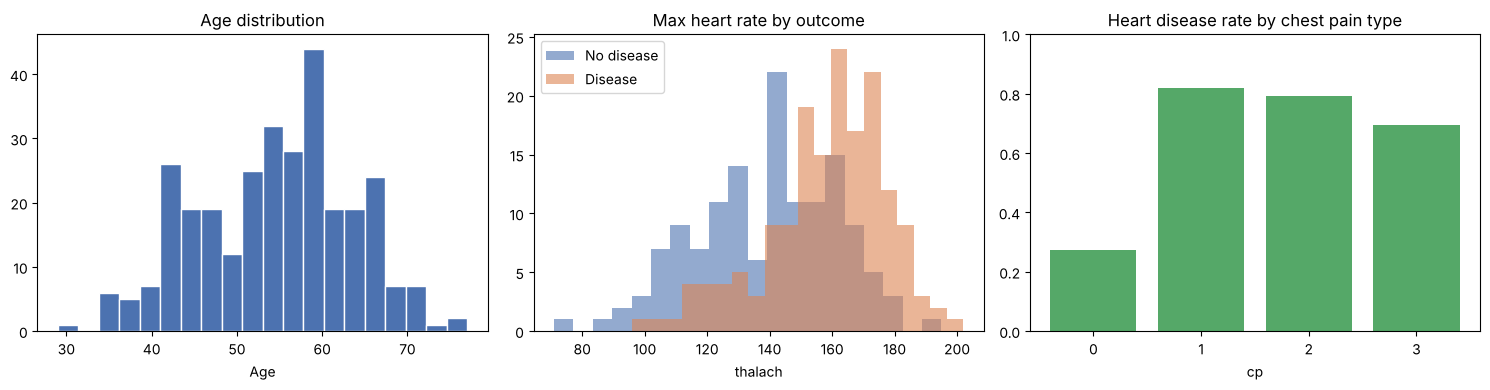

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['age'], bins=20, color='#4C72B0', edgecolor='white')
axes[0].set_title('Age distribution'); axes[0].set_xlabel('Age')

for t, c, lab in [(0, '#4C72B0', 'No disease'), (1, '#DD8452', 'Disease')]:
    axes[1].hist(df.loc[df.target == t, 'thalach'], bins=20, alpha=0.6, color=c, label=lab)
axes[1].set_title('Max heart rate by outcome'); axes[1].set_xlabel('thalach'); axes[1].legend()

rate = df.groupby('cp')['target'].mean()
axes[2].bar(rate.index.astype(str), rate.values, color='#55A868')
axes[2].set_title('Heart disease rate by chest pain type'); axes[2].set_xlabel('cp'); axes[2].set_ylim(0, 1)
plt.tight_layout()

exang      -0.44
oldpeak    -0.43
ca         -0.39
thal       -0.34
sex        -0.28
age        -0.23
trestbps   -0.14
chol       -0.09
fbs        -0.03
restecg     0.14
slope       0.35
thalach     0.42
cp          0.43
Name: target, dtype: float64


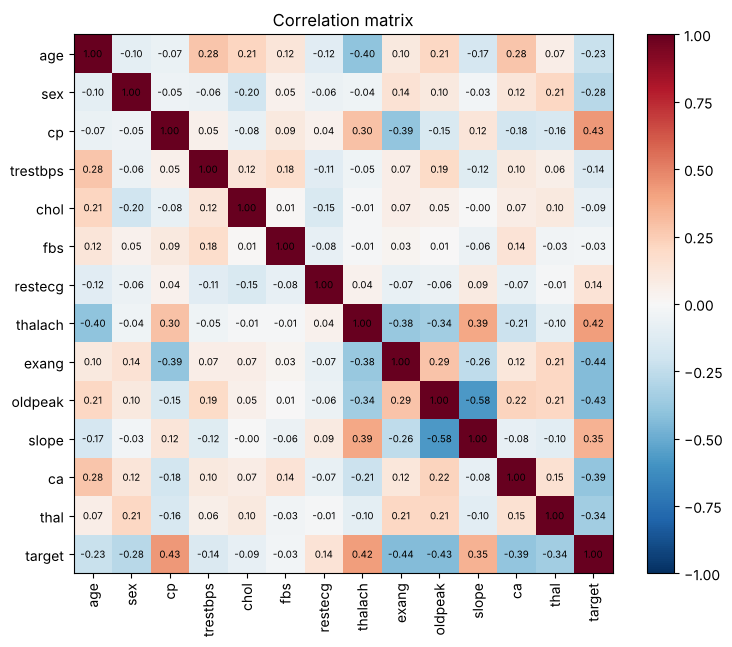

In [3]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Correlation matrix')
print(corr['target'].drop('target').sort_values().round(2))

**Observations:** chest pain type (`cp`), maximum heart rate (`thalach`) and ST slope are positively associated with the target; exercise angina (`exang`), ST depression (`oldpeak`), vessel count (`ca`) and `thal` are negatively associated. Age is negatively correlated with maximum heart rate.

The file has one duplicate row; it is kept so the split matches the original project results.

## Modeling
70/30 train-test split. `cp`, `restecg`, `slope`, `ca` and `thal` are categorical codes, so the improved model one-hot encodes them and scales the numeric features.

In [4]:
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

categorical = ['cp', 'restecg', 'slope', 'ca', 'thal']
numeric = [c for c in X.columns if c not in categorical]
preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)])

models = {
    'Majority-class baseline': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(random_state=0),
    'Logistic Regression (raw features)': LogisticRegression(max_iter=5000),
    'Random Forest': RandomForestClassifier(n_estimators=500, random_state=0),
    'Logistic Regression (scaled + one-hot)': make_pipeline(preprocess, LogisticRegression(max_iter=5000, C=0.1)),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'CV accuracy (10-fold)': cross_val_score(m, X, y, cv=cv).mean(),
        'CV ROC-AUC (10-fold)': cross_val_score(m, X, y, cv=cv, scoring='roc_auc').mean(),
    })
results = pd.DataFrame(rows).set_index('Model').round(3)
print(results.to_string())

                                        Accuracy  ROC-AUC  Precision  Recall     F1  CV accuracy (10-fold)  CV ROC-AUC (10-fold)
Model                                                                                                                           
Majority-class baseline                    0.516    0.500      0.516   1.000  0.681                  0.545                 0.500
Decision Tree                              0.747    0.747      0.761   0.745  0.753                  0.746                 0.744
Logistic Regression (raw features)         0.813    0.886      0.778   0.894  0.832                  0.822                 0.896
Random Forest                              0.835    0.910      0.796   0.915  0.851                  0.829                 0.904
Logistic Regression (scaled + one-hot)     0.846    0.912      0.824   0.894  0.857                  0.848                 0.914


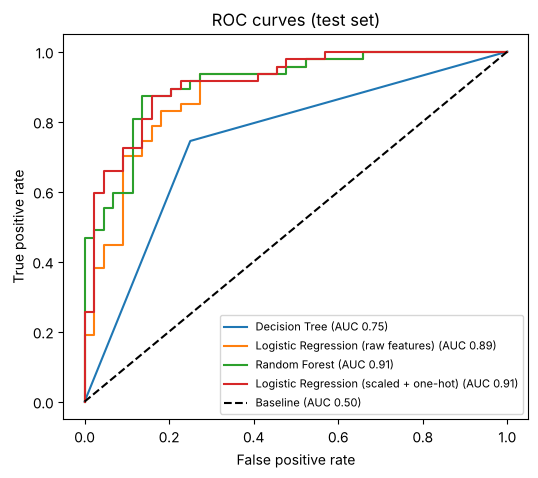

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ['Decision Tree', 'Logistic Regression (raw features)', 'Random Forest', 'Logistic Regression (scaled + one-hot)']:
    fpr, tpr, _ = roc_curve(y_test, models[name].predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], 'k--', label='Baseline (AUC 0.50)')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves (test set)')
ax.legend(fontsize=8)

Confusion matrix (rows = actual, cols = predicted):
            No disease  Disease
No disease          35        9
Disease              5       42


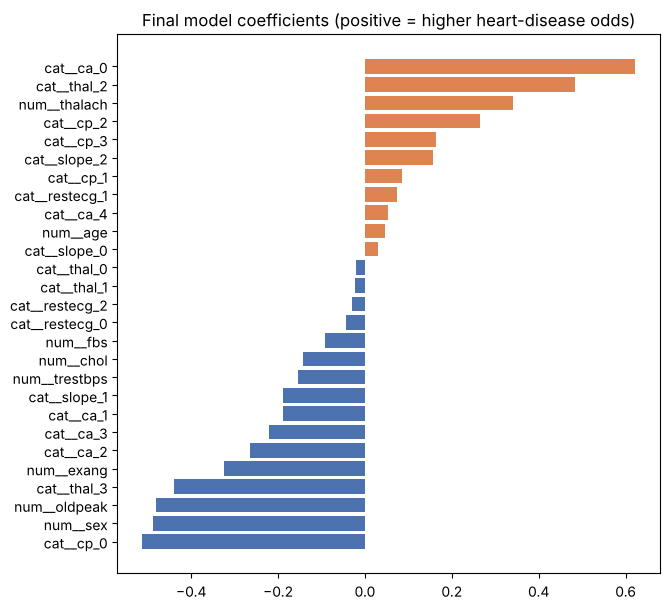

In [6]:
final = models['Logistic Regression (scaled + one-hot)']
cm = confusion_matrix(y_test, final.predict(X_test))
print('Confusion matrix (rows = actual, cols = predicted):')
print(pd.DataFrame(cm, index=['No disease', 'Disease'], columns=['No disease', 'Disease']))

names = final.named_steps['columntransformer'].get_feature_names_out()
coefs = pd.Series(final.named_steps['logisticregression'].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values > 0, '#DD8452', '#4C72B0'))
ax.set_title('Final model coefficients (positive = higher heart-disease odds)')

## Results

| Model | Test accuracy | ROC-AUC |
|---|---|---|
| Majority-class baseline | 0.52 | 0.50 |
| Decision Tree | 0.75 | 0.75 |
| Logistic Regression (raw features) | 0.81 | 0.89 |
| **Logistic Regression (scaled + one-hot)** | **0.85** | **0.91** |

- Logistic regression improved accuracy from a **0.52 baseline to 0.85**, with **0.91 ROC-AUC**; 10-fold cross-validation (0.85 accuracy, 0.91 AUC) confirms the result is not a lucky split.
- One-hot encoding the categorical clinical codes added about 3 points of accuracy over raw features.
- Recall is high (about 0.89), which matters in screening: few true heart-disease cases are missed.
- Strongest signals in the final model: number of major vessels (`ca`), chest pain type, `thal` result, sex, ST depression (`oldpeak`) and maximum heart rate.